# Why is piston 2 the easiest piston?

In `workbench.ipynb` piston 2 is estimated better than the other four by
almost every model at one wavelength: the Zernike-importance plot of A5, the
per-piston RMSE of the MLPs (about 3 nm against 8 nm with 36000 samples at
800 nm), and the per-wavelength models of B3 and C2. This notebook asks why:
is it the clocking of the lantern's output cores with respect to the M4
petals, or something else?

**Short answer: it is the pupil's twin symmetry, combined with the choice of
the reference petal. The clocking is not the cause.**

- **The twin.** A phase phi(x) and its twin -phi(-x) (rotated by 180 degrees
  and negated) give the same focal-plane intensity for a point-symmetric
  pupil. The lantern tells them apart only through the phases its modes pick
  up. How well it does so swings with the wavelength. At 800 nm it mostly
  does, but not for large, nearly point-symmetric configurations. Their twin is their own sign flip, and there the signals
  come close to a fold: +p and -p look alike.
- **Why piston 2 escapes.** The twin swaps opposite petals, so the
  differences between opposite petals are the only piston combinations it
  leaves unchanged. Petal 2 is opposite the reference petal, so piston 2 is
  one of them. Near a fold the estimates go wrong only along the other,
  twin-odd, combinations, and piston 2 stays right.
- **Where the advantage lives.** The bulk errors are the same for all
  pistons. Piston 2's advantage is entirely in rare large errors, and it
  disappears once the 2% most point-symmetric configurations are left out.
- **Not the clocking.** Moving the reference to another petal moves the easy
  piston to the petal opposite it.

The evidence below:

1. The observation.
2. The geometry of the pupil and the lantern.
3. The twin symmetry.
4. Simulations of how well the lantern separates twins, and of the signals
   along lines through the flat wavefront.
5. Where the large errors occur.
6. The twin-invariant combinations.
7. Moving the reference petal.
8. The wavelength dependence.

The heavy computations are in `scripts/piston2_twins.py` (simulations) and
`scripts/piston2_reref.py` (trainings), run by `scripts/run_piston2.sh`. The
helpers are in `ml_reconstruct/petals.py` and `ml_reconstruct/piston2.py`.

In [1]:
import os
os.environ["CBEAM_BACKEND"] = "numpy"

import numpy as np
import matplotlib.pyplot as plt
import ml_reconstruct as ml
from ml_reconstruct import petals
from ml_reconstruct.piston2 import *
from ml_reconstruct.notebook import load_hpo_runs, rescore_mlp

HPO_DIR, P2_DIR = "data/ml/mlp_hpo", "data/ml/piston2"

## 1. The observation

The 4 x 256 MLPs of the workbench's Part C at 800 nm (+-300 nm), rescored on
the 10000 validation rows of the 50000-sample dataset: one network trained
on 7200 samples, and the ensemble of 5 trained on 36000. Next to them are
the per-wavelength MLPs (3 x 128, wrapped-piston RMSE averaged over the 41
wavelengths) and their 5 nm unwrap.

In [2]:
ds50 = ml.LanternDataset.load("data/ml/single_800nm_50k.npz")
VA, C50 = slice(ds50.n_train, None), ds50.val[1]
ens = [f"800nm-50k-d4w256-cos3e-4-e2000-n36000-s{s}" for s in range(5)]
P_ens = rescore_mlp(ens, HPO_DIR, ds50, VA, 36000)
P_one = rescore_mlp(["800nm-50k-d4w256-cos3e-4-e2000-n7200-s0"], HPO_DIR, ds50, VA, 7200)
display(piston_error_table({"ensemble, 36000": (P_ens, C50), "single, 7200": (P_one, C50)}).round(2))

,RMSE p0,RMSE p1,RMSE p2,RMSE p3,RMSE p4,median p0,median p1,median p2,median p3,median p4
"ensemble, 36000",7.73,7.79,3.07,6.64,8.20,0.27,0.28,0.30,0.25,0.27
"single, 7200",10.56,10.98,7.39,10.69,10.02,0.99,0.97,0.91,0.95,1.02


In [3]:
runs = load_hpo_runs(HPO_DIR)
wl_err = np.stack(runs.query("role == 'perwl' and depth == 3 and width == 128").val_rmse.to_numpy())
unw = runs.query("role == 'unwrap' and scenario == '5nm' and depth == 3 and width == 128").val_rmse.iloc[0]
print("per-wavelength MLP 3x128, wrapped RMSE averaged over the wavelengths:", wl_err.mean(0).round(2))
print("their 5 nm unwrap:                                                   ", np.round(unw, 3))

per-wavelength MLP 3x128, wrapped RMSE averaged over the wavelengths: [2.99 3.01 2.66 2.98 3.02]
their 5 nm unwrap:                                                    [0.45  0.449 0.418 0.453 0.454]


At one wavelength piston 2 has about 2.5x lower RMSE, but the **median**
errors are the same for all five pistons. The difference is in the tails:
rare, large errors that spare piston 2. With 41 wavelengths and the unwrap
the difference nearly vanishes.

## 2. Geometry: petals and lantern

The five piston modes move one petal each. The reference petal R is the one
none of them moves. The lantern's 19 output cores lie on a hexagonal grid
whose first ring points along 0, 60, 120 ... degrees, the directions of the
petal centres. So the clocking is "aligned", and it is the same for every
petal: a 6-fold symmetric lantern cannot single one petal out. The reference
can.

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython
p0: centre at  -120.0 deg, 18095 px, opposite p3
p1: centre at  -180.0 deg, 18336 px, opposite p4
p2: centre at   119.8 deg, 18176 px, opposite R
p3: centre at    59.8 deg, 18229 px, opposite p0
p4: centre at    -0.0 deg, 18109 px, opposite p1
R : centre at   -59.6 deg, 18151 px, opposite p2


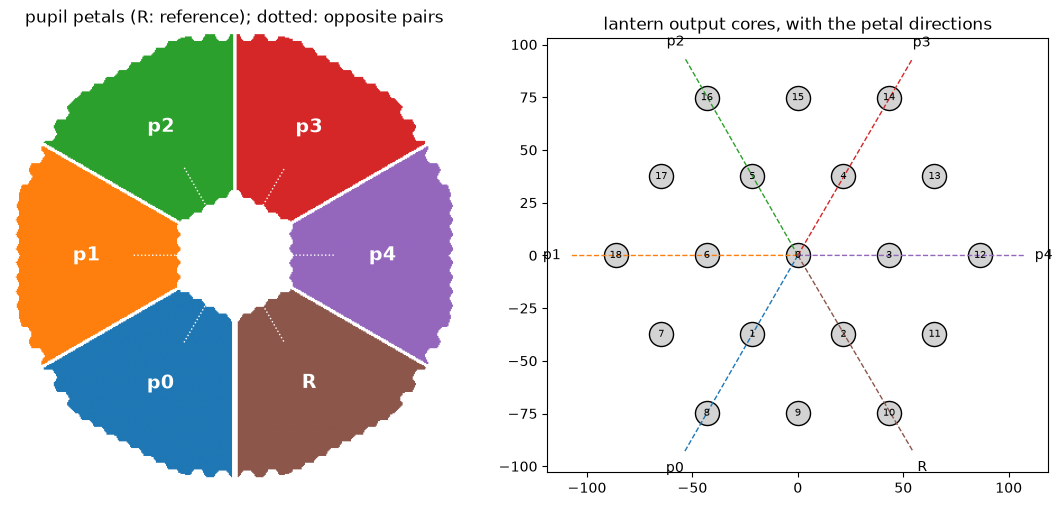

In [4]:
from ml_reconstruct.simulate import bp
p800 = bp.get_simulation_parameters(3, 0.8)
ifunc = bp.load_ifunc(p800["ifunc_file"]); bp.center_ifunc_mask(ifunc)
geom = petals.petal_geometry(ifunc.mask_inf_func, np.asarray(ifunc.influence_function))
for k in range(6):
    print(f"{'R ' if k == geom['ref'] else f'p{k}'}: centre at {geom['angle_deg'][k]:7.1f} deg, "
          f"{geom['n_px'][k]} px, opposite {'R' if geom['opposite'][k] == geom['ref'] else 'p%d' % geom['opposite'][k]}")
plot_pupil_and_lantern(geom, ds50.core_xy)

In [5]:
mask = np.asarray(ifunc.mask_inf_func) > 0
rot = np.roll(mask[::-1, ::-1], (1, 1), axis=(0, 1))          # 180-degree rotation about the FFT centre
print(f"pupil mask point-symmetric about the FFT centre: {np.mean(mask == rot):.4%} of the pixels "
      f"({np.sum(mask != rot)} differ)")

pupil mask point-symmetric about the FFT centre: 98.7275% of the pixels (2036 differ)


## 3. The twin symmetry

For a pupil field A(x) exp(i phi(x)) with A(-x) = A(x), the twin phase
-phi(-x) gives the focal-plane field conj(E(u)), the complex conjugate. It
has the same intensity, so a pure intensity sensor cannot tell the two apart
(this is also why the sign of an even aberration such as defocus is
invisible in focus). The lantern projects the field on its modes. Those are
real, so the twin's mode amplitudes are the conjugates of the original ones.
Its output powers differ only through the phases the modes accumulate along
the lantern: a lantern with a real transfer matrix would be exactly blind to
the twin.

For petal pistons the 180-degree rotation swaps opposite petals. With the
reference petal fixed at 0, the twin of the pistons p is the linear map
T p, with p'_k = p_opp(R) - p_opp(k). It leaves unchanged exactly the
differences between opposite petals: p0 - p3, p1 - p4 and p2 - p_R = p2.
It negates the twin-odd combinations p0 + p3 - p2 and p1 + p4 - p2.

In [6]:
T = petals.twin_matrix(geom["opposite"], geom["ref"])
print("T =\n", T.astype(int), "\nT @ T = I:", np.allclose(T @ T, np.eye(5)))
combos = twin_combinations(T, geom["opposite"], geom["ref"])
for name, a in combos.items():
    print(f"  {name:14s} {'invariant' if np.allclose(a @ T, a) else 'odd':9s} {a.round(3)}")

T =
 [[ 0  0  1 -1  0]
 [ 0  0  1  0 -1]
 [ 0  0  1  0  0]
 [-1  0  1  0  0]
 [ 0 -1  1  0  0]] 
T @ T = I: True
  p0 - p3        invariant [ 0.707  0.     0.    -0.707  0.   ]
  p1 - p4        invariant [ 0.     0.707  0.     0.    -0.707]
  p2 - p_ref     invariant [0. 0. 1. 0. 0.]
  p0 + p3 - p2   odd       [ 0.577  0.    -0.577  0.577  0.   ]
  p1 + p4 - p2   odd       [ 0.     0.577 -0.577  0.     0.577]


### 3b. The twin in the focal plane: two examples

Two configurations from the 800 nm validation set, each with its twin T p:

- **Typical** (row 45938). Its twin also lies inside the +-300 nm training
  range, and the ensemble of section 1 estimates it to 1 nm.
- **Critical** (row 43822). It is nearly point-symmetric, so its twin is
  close to its sign flip -p. The ensemble returned almost exactly -p (section
  5).

For each configuration the rows show the pupil phase, then the focal-plane
intensity and phase of the field that reaches the lantern. The twin has the
same intensity and the opposite phase (the complex conjugate). The lantern
sees only the field over its input face (dashed circle).

In [7]:
ex = np.load(f"{P2_DIR}/camera_examples_800nm.npz")      # scripts/piston2_twins.py --family examples
configs = dict(zip(ex["names"], ex["coeff"]))
E, ext = focal_fields(ifunc, p800, np.array(list(configs.values())))
idx = {n: i for i, n in enumerate(configs)}
for a, b in [("typical: p", "typical: Tp"), ("critical: p", "critical: Tp"), ("critical: p", "critical: -p")]:
    Ia, Ib = np.abs(E[idx[a]]) ** 2, np.abs(E[idx[b]]) ** 2
    dph = np.angle(E[idx[a]] * E[idx[b]])[Ia > 1e-3 * Ia.max()]      # 0 if phase(b) = -phase(a)
    print(f"{a:12s} vs {b:13s}: max intensity difference {np.abs(Ia - Ib).max() / Ia.max():.1e} of the peak, "
          f"median |phase(a) + phase(b)| {np.median(np.abs(dph)):.2f} rad")
print("ensemble estimate of the critical p:", P_ens[43822 - 40000].round(0), " truth:", configs["critical: p"].round(0))

typical: p   vs typical: Tp  : max intensity difference 1.1e-02 of the peak, median |phase(a) + phase(b)| 0.04 rad
critical: p  vs critical: Tp : max intensity difference 1.8e-02 of the peak, median |phase(a) + phase(b)| 0.26 rad
critical: p  vs critical: -p : max intensity difference 2.6e-01 of the peak, median |phase(a) + phase(b)| 0.13 rad
ensemble estimate of the critical p: [ 265. -244.   -8.  227. -244.]  truth: [-276.  235.   33. -260.  270.]


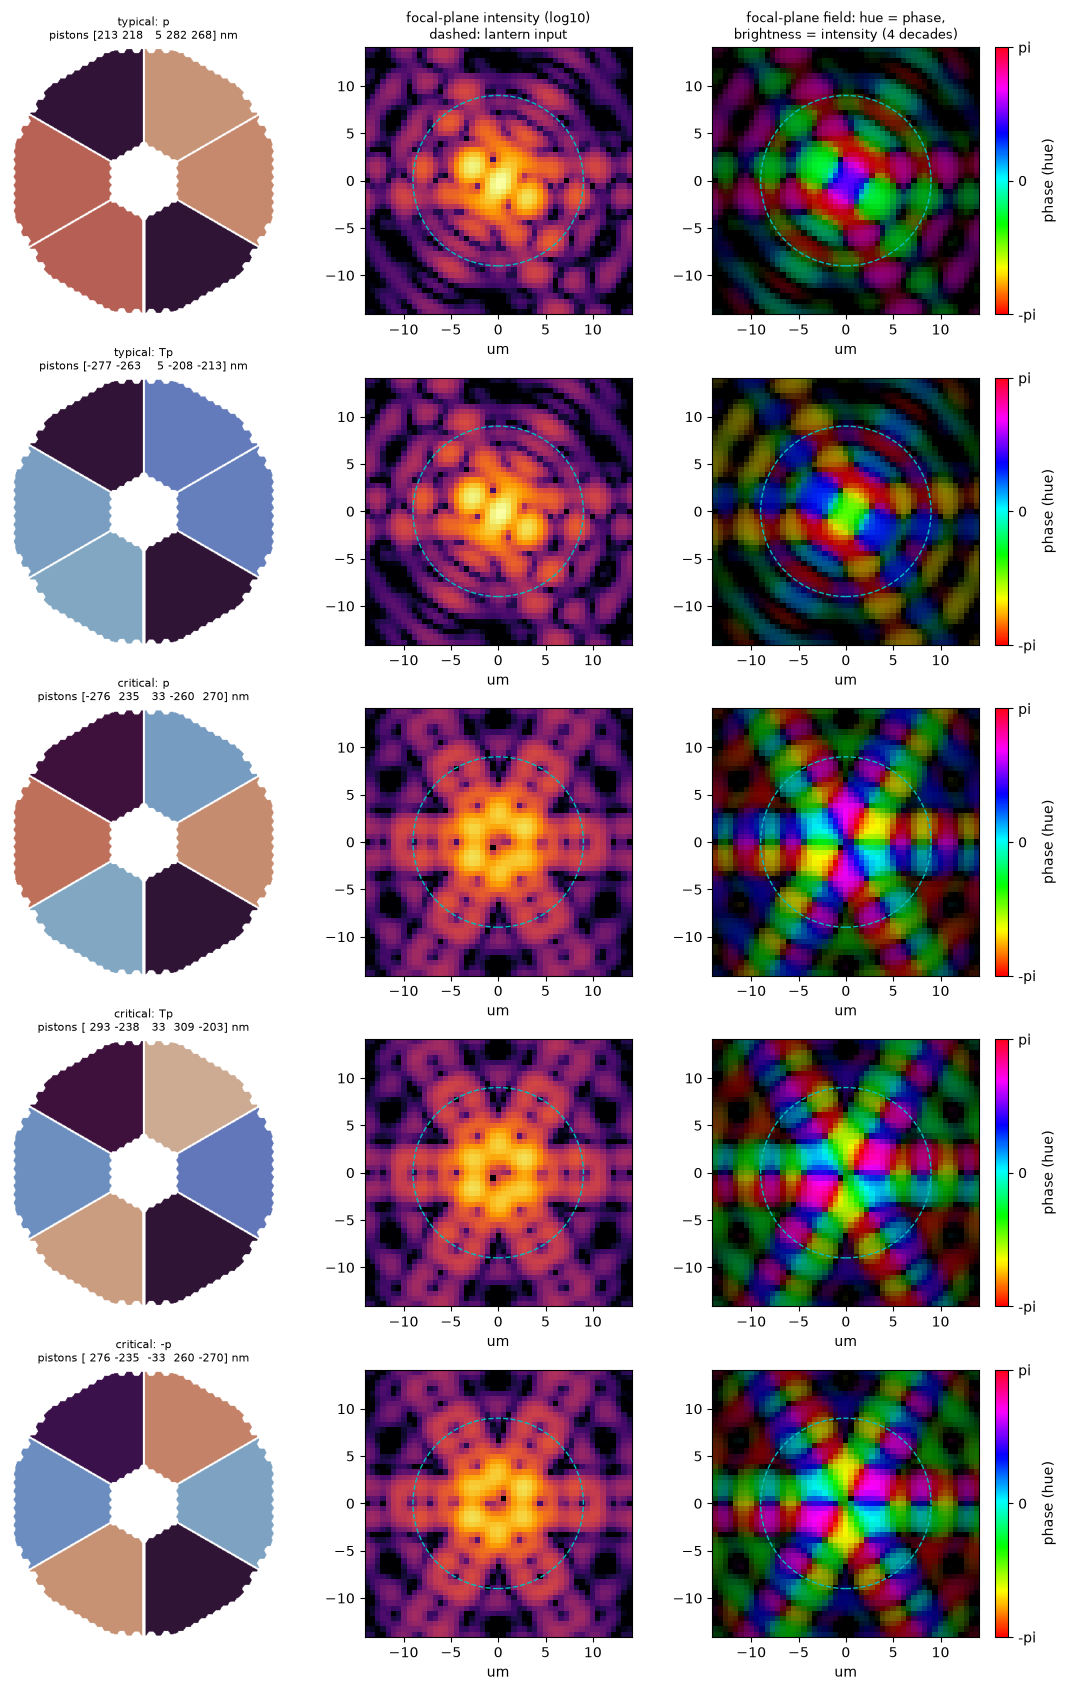

In [8]:
show = ["typical: p", "typical: Tp", "critical: p", "critical: Tp", "critical: -p"]
plot_twin_psfs(geom, {n: configs[n] for n in show}, E[[idx[n] for n in show]], ext, 800.0)

The lantern's camera signals of the same configurations. Distances are in
units of the median distance between two random training configurations, so
1 is "as different as two unrelated configurations".

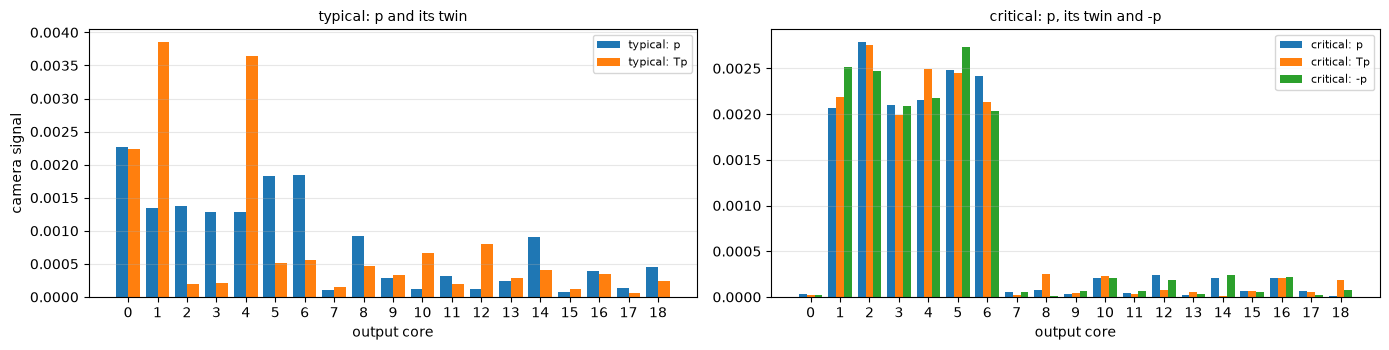

,typical: p,typical: Tp,typical: -p,critical: p,critical: Tp,critical: -p
typical: p,0.00,1.05,1.06,0.81,0.82,0.81
typical: Tp,1.05,0.00,0.29,1.29,1.23,1.22
typical: -p,1.06,0.29,0.00,1.30,1.22,1.22
critical: p,0.81,1.29,1.30,0.00,0.14,0.18
critical: Tp,0.82,1.23,1.22,0.14,0.00,0.18
critical: -p,0.81,1.22,1.22,0.18,0.18,0.00


In [9]:
plot_example_signals(ex, {"typical: p and its twin": ["typical: p", "typical: Tp"],
                          "critical: p, its twin and -p": ["critical: p", "critical: Tp", "critical: -p"]})
display(signal_distance_table(ex, ds50.signals[:2000]).round(2))

**Typical case.** The twin has the same focal-plane intensity, to 1% of the
peak (the pupil mask's residual asymmetry), and the conjugate phase. Yet the
lantern's outputs differ as much as those of two unrelated configurations
(distance 1.05). The modal phases break the twin, so the network has no
trouble.

**Critical case.** The PSF has a dark centre, with the light spread around a
ring. The lantern puts almost all of it into the six cores of the first ring,
nearly equally, and the central core stays dark. p, its twin and -p differ
only by 0.14-0.18, mostly in the weak outer cores. This is the near-fold of
section 4: the sign of the configuration's twin-odd part is almost invisible,
and the network returned close to -p.

## 4. How well does the lantern separate twins?

`scripts/piston2_twins.py` simulates 400 random configurations p (+-150 nm,
so that their twins stay within +-300 nm), their twins T p, and controls
p + D. Each control is at the same distance |D| = |T p - p| in a random
direction that, like the twin, leaves piston 2 unchanged. The simulation
covers the channel powers at 21 wavelengths and the 800 nm camera signals.
It also simulates 200 exactly point-symmetric configurations, whose twin is
-p. The twin ratio |s(p) - s(Tp)| / |s(p) - s(p+D)| is 1 if the twin is as
distinguishable as any configuration that far away, and 0 if it is
invisible.

### Twins are mostly distinguishable

A ratio well below 1 everywhere would mean a global blind spot.

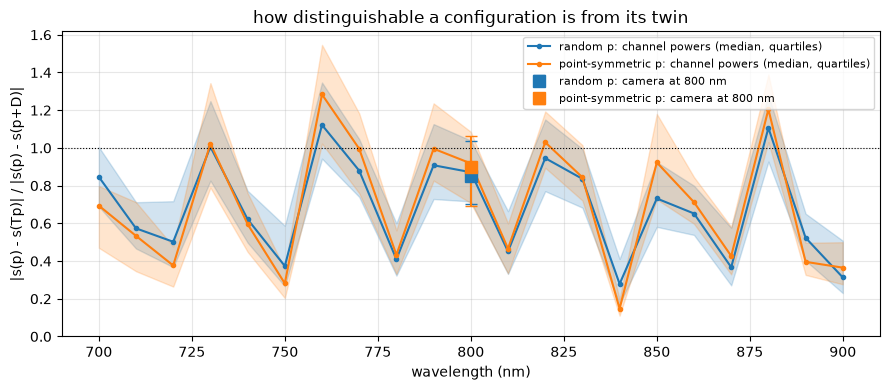

random           camera 800 nm: median twin ratio 0.852 (quartiles 0.700-1.034)
point-symmetric  camera 800 nm: median twin ratio 0.898 (quartiles 0.694-1.063)


In [10]:
twins_random, twins_even = load_twin_ratios(P2_DIR), load_twin_ratios(P2_DIR, "_even")
plot_twin_ratios({"random p": twins_random, "point-symmetric p": twins_even})
for label, (by_wl, cam) in [("random", twins_random), ("point-symmetric", twins_even)]:
    if cam is not None:
        print(f"{label:16s} camera 800 nm: median twin ratio {np.median(cam):.3f} "
              f"(quartiles {np.percentile(cam, 25):.3f}-{np.percentile(cam, 75):.3f})")

At 800 nm, the wavelength of the single-wavelength models, the ratio is
0.7-1 for both kinds of configuration, in the channel powers and in the
camera signals alike. A twin is somewhat closer than an arbitrary
configuration at the same distance, but far from invisible: there is no
global blind spot. Across the band, though, the ratio swings strongly with
the wavelength, from about 0.15 at 840 nm (twins nearly indistinguishable)
to about 1.2 at 760 and 880 nm. The modal phases that break the twin change
with the wavelength.

### Folds along point-symmetric directions

Configurations hundreds of nm apart look different anyway, so the ratio says
little about a local ambiguity. What makes an estimate fail is a fold, where
the signals are nearly the same for +t and -t along some line. The twin
predicts one along point-symmetric directions v (T v = -v), whose twin is
-v. `scripts/piston2_twins.py --family lines` simulates 25 points along each
of 20 lines t v through the flat wavefront, for point-symmetric,
twin-invariant and random directions. The plot shows the asymmetry
|s(tv) - s(-tv)| / |s(tv) - s(0)|: about 2 for a linear response, 0 for a
perfect fold.

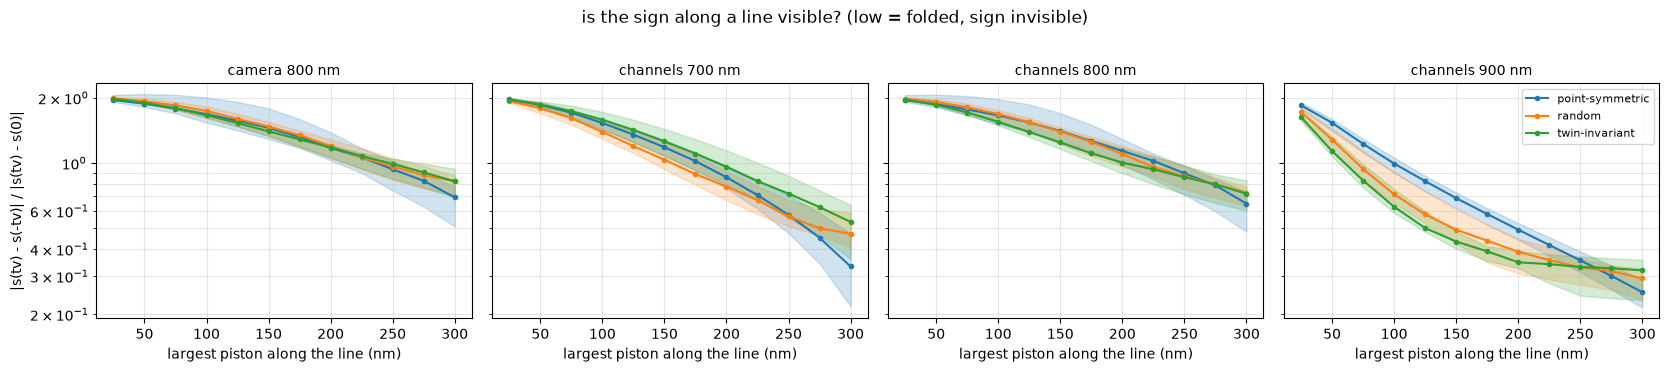

camera 800 nm    least asymmetric line at 300 nm: point-symmetric 0.09, random 0.55, twin-invariant 0.46
channels 700 nm  least asymmetric line at 300 nm: point-symmetric 0.11, random 0.28, twin-invariant 0.22
channels 800 nm  least asymmetric line at 300 nm: point-symmetric 0.08, random 0.50, twin-invariant 0.39
channels 900 nm  least asymmetric line at 300 nm: point-symmetric 0.04, random 0.18, twin-invariant 0.15


In [11]:
lines = load_lines(P2_DIR)
plot_folds(lines)
for label, d in lines.items():
    folds = {k: A[:, -1].min() for k, (t, A) in fold_asymmetry(d).items()}
    print(f"{label:16s} least asymmetric line at 300 nm: " + ", ".join(f"{k} {v:.2f}" for k, v in folds.items()))

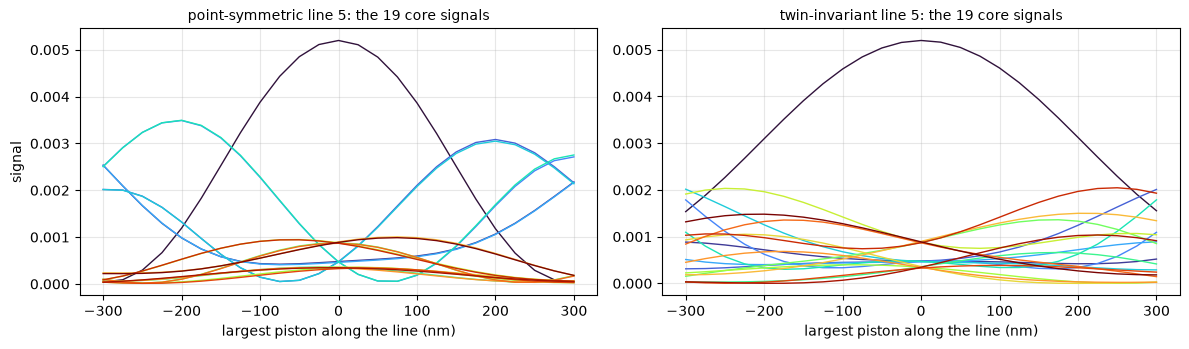

In [12]:
d800 = lines["camera 800 nm"]
worst = int(np.argmin(fold_asymmetry(d800)["point-symmetric"][1][:, -1]))
plot_line_signals(d800, line=worst)

Near the flat wavefront the response is linear in every direction: the
asymmetry is about 2 and the sign is visible. At large amplitudes every kind
of line becomes more symmetric. Only some point-symmetric lines come close to
a true fold (asymmetry below 0.1 at 300 nm); no twin-invariant or random line
does. These are the configurations where a network can mistake +p for -p.

## 5. Where do the large errors occur?

The odd part |p + T p| / 2 of a configuration (modulo lambda) is 0 for a
point-symmetric phase, whose twin is then its sign flip -p. That twin lies
inside the training range, so it is a real alternative for the network.
Binned by the odd part, the errors of pistons 0, 1, 3 and 4 explode on the
most point-symmetric configurations, while piston 2's do not.

,bin,odd_nm,n,p0,p1,p2,p3,p4,> 50 nm %
0,0-2%,8-95,200,47.75,42.76,4.57,42.39,45.42,2.50
1,2-5%,95-131,300,1.47,0.71,0.67,0.97,0.92,0.00
2,5-10%,131-168,500,2.27,0.62,0.65,1.46,1.04,0.00
3,10-25%,168-230,1500,1.93,3.62,5.28,4.13,1.49,0.13
4,25-50%,230-268,2500,7.18,9.30,3.77,4.54,10.06,0.12
5,50-100%,268-386,5000,0.92,0.93,1.59,0.82,0.80,0.02


,bin,odd_nm,n,p0,p1,p2,p3,p4,> 50 nm %
0,0-2%,8-95,200,53.61,46.62,4.63,52.56,47.97,3.00
1,2-5%,95-131,300,6.35,6.94,3.14,6.69,8.69,1.00
2,5-10%,131-168,500,3.60,3.13,5.22,4.56,3.62,0.40
3,10-25%,168-230,1500,11.97,9.85,11.06,11.43,7.61,0.80
4,25-50%,230-268,2500,8.42,10.10,6.11,6.97,11.05,0.48
5,50-100%,268-386,5000,5.09,8.39,7.04,7.07,4.96,0.50


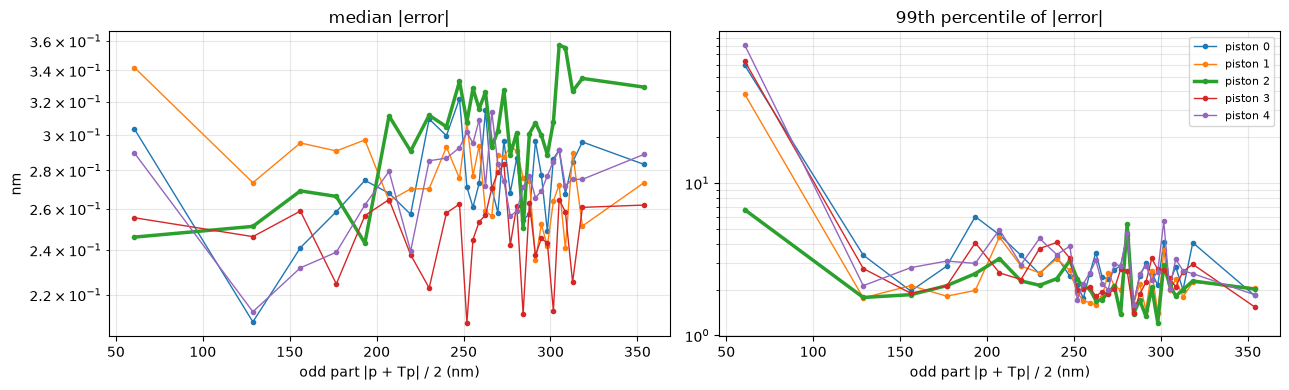

In [13]:
display(errors_by_odd_part(P_ens, C50, T, 800.0).round(2))
display(errors_by_odd_part(P_one, C50, T, 800.0).round(2))
plot_errors_vs_odd_part(P_ens, C50, T, 800.0)

In [14]:
odd = odd_part(C50, T, 800.0)
for q in (0, 2, 5):
    m = odd > np.percentile(odd, q)
    print(f"without the {q}% most point-symmetric configurations: RMSE per piston "
          f"ensemble {ml.rmse_nm(P_ens[m], C50[m]).round(2)}, single {ml.rmse_nm(P_one[m], C50[m]).round(2)}")

without the 0% most point-symmetric configurations: RMSE per piston ensemble [7.73 7.79 3.07 6.64 8.2 ], single [10.56 10.98  7.39 10.69 10.02]
without the 2% most point-symmetric configurations: RMSE per piston ensemble [3.81 4.96 3.04 2.89 5.16], single [7.43 8.87 7.43 7.76 7.45]
without the 5% most point-symmetric configurations: RMSE per piston ensemble [3.86 5.03 3.08 2.93 5.23], single [7.46 8.93 7.53 7.8  7.41]


In [15]:
out = np.flatnonzero(np.abs(P_ens - C50).max(1) > 50)
print(f"{len(out)} estimates of the ensemble off by > 50 nm; their pistons (truth / estimate / -truth):")
for i in out[:8]:
    print("  ", C50[i].round(0), " ", P_ens[i].round(0), " ", (-C50[i]).round(0))

11 estimates of the ensemble off by > 50 nm; their pistons (truth / estimate / -truth):
   [ 288. -277.   16.  254. -290.]   [ 169. -228.   15.  159. -187.]   [-288.  277.  -16. -254.  290.]
   [-276.  235.   33. -260.  270.]   [ 265. -244.   -8.  227. -244.]   [ 276. -235.  -33.  260. -270.]
   [-279.  231.   62. -279.  236.]   [  98. -119.   27.   44.  -67.]   [ 279. -231.  -62.  279. -236.]
   [-282.  254.  157. -191.  295.]   [  26. -171.  -12.   14. -155.]   [ 282. -254. -157.  191. -295.]
   [ 294. -222. -265.  236. -262.]   [ 267. -221. -167.  215. -268.]   [-294.  222.  265. -236.  262.]
   [ 277. -265.   40.  291. -272.]   [ 239. -248.   36.  227. -238.]   [-277.  265.  -40. -291.  272.]
   [-270.  200.  165. -284.  296.]   [-258.  197.  148. -277.  214.]   [ 270. -200. -165.  284. -296.]
   [-293.  214.  166. -184.  283.]   [-116.   27.   92.  -94.   76.]   [ 293. -214. -166.  184. -283.]


## 6. The twin-invariant combinations are all easy

If the twin is the cause, piston 2 is not special in itself. All three
twin-invariant combinations should be as accurate as piston 2, and the
errors should sit in the twin-odd ones. Each combination is a unit vector,
so the numbers are comparable.

In [16]:
display(combination_errors({"ensemble, 36000": (P_ens, C50), "single, 7200": (P_one, C50)}, combos).round(2))

rmse                       median               \
model        ensemble, 36000 single, 7200 ensemble, 36000 single, 7200   
combination                                                              
p0 + p3 - p2            9.09        11.80            0.27         0.95   
p0 - p3                 1.97         7.98            0.24         0.88   
p1 + p4 - p2            8.38        11.00            0.28         0.97   
p1 - p4                 1.80         7.18            0.24         0.94   
p2 - p_ref              3.07         7.39            0.30         0.91   

                         p99               
model        ensemble, 36000 single, 7200  
combination                                
p0 + p3 - p2            2.84        19.70  
p0 - p3                 2.25        16.88  
p1 + p4 - p2            2.73        17.09  
p1 - p4                 2.36        16.33  
p2 - p_ref              2.30        13.47

## 7. Moving the reference

The decisive test for the clocking question. `scripts/piston2_reref.py`
retrains the 4 x 256 MLP on the same signals (18000 samples) with the
pistons expressed relative to each of the six petals in turn: same
configurations, same signals, different reference. If the lantern's
clocking made one petal easy, the easy piston would stay on that petal. If
it is the twin symmetry, the easy piston is the one opposite the reference,
whatever the reference.

,petal 0,petal 1,petal 2,petal 3,petal 4,petal 5,easiest,opposite of ref
reference petal,,,,,,,,
0,NaN,15.91,9.66,5.24,17.33,8.10,3.0,3.0
1,14.14,NaN,7.99,15.37,5.73,7.91,4.0,4.0
2,9.22,8.16,NaN,8.61,7.69,3.94,5.0,5.0
3,4.47,13.56,8.21,NaN,14.51,7.05,0.0,0.0
4,17.40,4.42,8.74,16.78,NaN,8.55,1.0,1.0
5,8.30,8.16,4.32,7.51,8.93,NaN,2.0,2.0


easiest petal = the one opposite the reference, for every reference: True


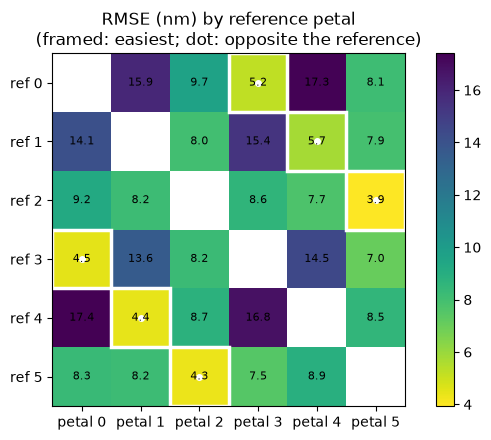

In [17]:
reref = reref_table(P2_DIR, geom["opposite"])
display(reref.round(2))
print("easiest petal = the one opposite the reference, for every reference:",
      bool((reref["easiest"] == reref["opposite of ref"]).all()))
plot_reref(reref)

The easy piston follows the reference, so the cause is the pupil's symmetry
and the reference, not the lantern's clocking.

There is also a secondary pattern. With the reference in the pair (2, 5),
the other four petals are all alike. With the reference in (0, 3) or
(1, 4), the remaining pair other than (2, 5) is the worst. This is most
likely an effect of the dataset rather than the physics: the configurations
were drawn with petal 5 as the reference, so after re-referencing the
pistons involving petal 5 stay uniform in +-300 nm, while the others become
differences of two uniform pistons (triangular in +-600 nm). It is a single
seed per reference, and is not pursued further.

## 8. Wavelength dependence

The twin is broken by the modal phases of the lantern, which change with
the wavelength. The per-wavelength MLPs of the workbench (Part C) show the
piston-2 advantage, RMSE(p0, p1, p3, p4) / RMSE(p2), at each wavelength. If
the twin drives it, the advantage should be largest where the simulated twin
ratio is lowest.

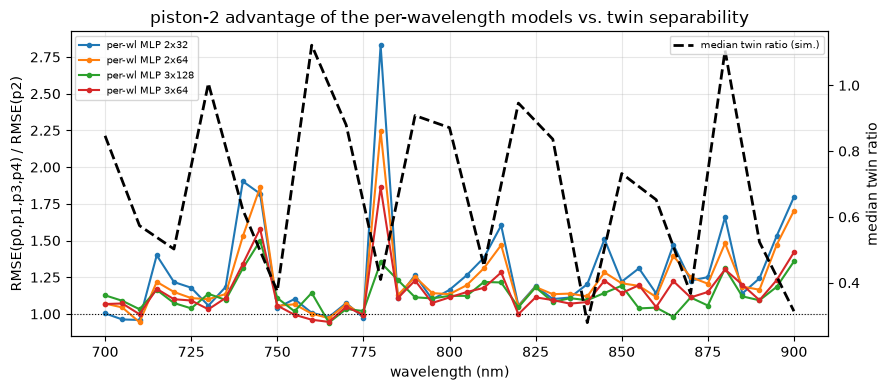

correlation of the 3x128 piston-2 advantage with the median twin ratio over 21 wavelengths: -0.16


In [18]:
ratio = perwl_piston_ratio(runs)
plot_ratio_vs_twin(ratio, twins_random[0])
by_wl = twins_random[0]
if by_wl:
    g = ratio[ratio.arch == "3x128"].set_index("wavelength_nm").ratio
    wl = [w for w in sorted(by_wl) if w in g.index]
    r = np.corrcoef([g[w] for w in wl], [np.median(by_wl[w]) for w in wl])[0, 1]
    print(f"correlation of the 3x128 piston-2 advantage with the median twin ratio over {len(wl)} wavelengths: {r:+.2f}")

The prediction fails. The piston-2 advantage of the per-wavelength models is
modest (1-1.5, with peaks at 745 and 780 nm) and does not follow the median
twin ratio: at 840 nm, where twins are least distinguishable, there is no
peak. That fits the rest of this notebook, where the advantage comes from
rare near-folds rather than from how distinguishable a typical twin is, but
it is not tested here and stays open.

## 9. Conclusions

**Not the clocking.** The lantern's hex core layout is aligned with the
petals and 6-fold symmetric, so it treats every petal alike. Moving the
reference to any other petal moves the easy piston to the petal opposite the
new reference (section 7, 6 of 6).

**The mechanism.** A point-symmetric pupil makes every phase
indistinguishable in focal-plane intensity from its twin -phi(-x).

- **Invariant combinations.** The twin leaves unchanged only the differences
  between opposite petals, and piston 2 is one of them because petal 2 faces
  the reference. All three such differences are equally easy: an RMSE of
  1.8-3.1 nm for the 36000-sample ensemble, against 8.4-9.1 nm for the two
  twin-odd combinations (section 6).
- **Where it bites.** The lantern breaks the twin through its modal phases,
  well at 800 nm for typical configurations. It comes close to a fold, where
  +p and -p look alike, only for large, nearly point-symmetric
  configurations (sections 4 and 5). These produce the rare large errors,
  all along the twin-odd directions.
- **Size of the effect.** The bulk errors are the same for all pistons
  (median about 0.3 nm). Leaving out the 2% most point-symmetric
  configurations removes the piston-2 advantage.

**Implications.**

- **Per-piston RMSE depends on the reference.** At one wavelength, the error
  of a petal's piston depends on which petal is the reference. A
  reference-free measure, such as the residual wavefront over the pupil or
  the errors in the twin-invariant / twin-odd combinations, describes a
  reconstructor better.
- **Remedies at one wavelength.** The error tail comes from the twin fold,
  so it can be reduced by breaking the pupil's point symmetry (an
  asymmetric stop, or a known static asymmetric phase as diversity), by
  oversampling nearly point-symmetric configurations in training, or by
  adding a wavelength. With 41 wavelengths and the unwrap, the advantage
  nearly disappears (0.42 against 0.45 nm).
- **Choosing wavelengths.** Twin separability swings strongly with the
  wavelength (0.15-1.2). For a few-wavelength sensor, the wavelengths near
  the lows (e.g. 840 nm) are the ones most exposed to the twin, so it is
  worth checking what each contributes.

**Open points.**

- The wavelength dependence of the per-wavelength models' advantage does not
  follow the median twin ratio (section 8).
- The secondary pattern of section 7 is probably a dataset effect, but rests
  on a single seed per reference.